   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2


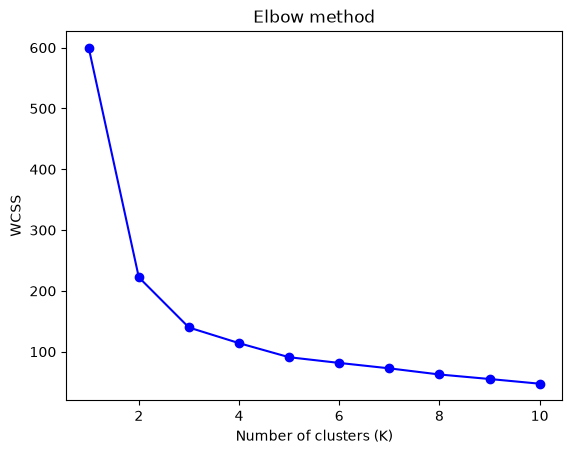


Cluster sizes: [53, 50, 47]
col_0        0   1   2
row_0                 
setosa       0  50   0
versicolor  39   0  11
virginica   14   0  36


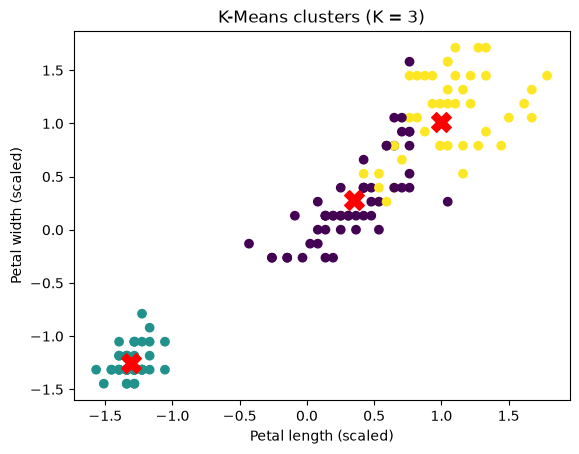

In [1]:
# Experiment 3: Clustering - K-Means on the Iris dataset
# Aim: Implement K-Means clustering and find the number of clusters using the Elbow method.
# Dataset: Iris dataset from scikit-learn

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

iris = load_iris()
X = pd.DataFrame(iris.data, columns=iris.feature_names)
print(X.head())

X_scaled = StandardScaler().fit_transform(X)

wcss = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X_scaled)
    wcss.append(km.inertia_)

plt.plot(range(1, 11), wcss, 'bo-')
plt.xlabel('Number of clusters (K)')
plt.ylabel('WCSS')
plt.title('Elbow method')
plt.show()

kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
labels = kmeans.fit_predict(X_scaled)

print("\nCluster sizes:", pd.Series(labels).value_counts().sort_index().tolist())
print(pd.crosstab(iris.target_names[iris.target], labels))

plt.scatter(X_scaled[:, 2], X_scaled[:, 3], c=labels, cmap='viridis')
plt.scatter(kmeans.cluster_centers_[:, 2], kmeans.cluster_centers_[:, 3], c='red', marker='X', s=200)
plt.xlabel('Petal length (scaled)')
plt.ylabel('Petal width (scaled)')
plt.title('K-Means clusters (K = 3)')
plt.show()